<a href="https://colab.research.google.com/github/uday68/CommandGrid-Theme/blob/main/machine_learning_algo_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [61]:
#linear regerssion implementation from scratch just using the numpy and pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns




In [62]:
#implemention of all the error metrics in this cell from scratch

def mse(Y_true,Y_pred):
  return np.mean((Y_true-Y_pred)**2)

def rmse(Y_true,Y_pred):
  return np.sqrt(mse(Y_true,Y_pred))
def mae(Y_true,Y_pred):
  return np.mean(np.abs(Y_true-Y_pred))

def r2_score(Y_true,Y_pred):
  mean_y_true = np.mean(Y_true)
  ss_total = np.sum((Y_true - mean_y_true)**2)
  ss_residual = np.sum((Y_true - Y_pred)**2)
  # Handle cases where ss_total is zero to prevent division by zero
  if ss_total == 0:
    return 1.0 if ss_residual == 0 else 0.0
  return 1 - (ss_residual / ss_total)

In [63]:

def least_square(y_true,y_pred):
    n = len(y_true)
    return (1/(2*n)) * np.sum(np.square(y_pred - y_true))

def hypothesis(X,theta):
  return np.dot(X,theta)




In [64]:
def initalize_parameters(n_features):
    theta = np.zeros((n_features,1))
    return theta

cost_history = []

def batch_compute_gradients(theta,X,y_true,learning_rate=0.01,n_iter=1000):
    n = len(y_true)

    for _ in range(n_iter):
        y_pred = hypothesis(X,theta)
        loss = least_square(y_true,y_pred)
        gradient = (1/n) * X.T.dot(y_pred - y_true)

        theta  = theta - learning_rate*gradient
        cost_history.append(loss)
    return theta,loss


In [65]:
def predict(X,theta):
    return hypothesis(X,theta)

In [66]:
import pandas as pd

url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
df = pd.read_csv(url)

print(df.head())


      crim    zn  indus  chas    nox     rm   age     dis  rad  tax  ptratio  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

        b  lstat  medv  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90   5.33  36.2  


In [67]:
df.info(),df.describe(),df.var()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


(None,
              crim          zn       indus        chas         nox          rm  \
 count  506.000000  506.000000  506.000000  506.000000  506.000000  506.000000   
 mean     3.613524   11.363636   11.136779    0.069170    0.554695    6.284634   
 std      8.601545   23.322453    6.860353    0.253994    0.115878    0.702617   
 min      0.006320    0.000000    0.460000    0.000000    0.385000    3.561000   
 25%      0.082045    0.000000    5.190000    0.000000    0.449000    5.885500   
 50%      0.256510    0.000000    9.690000    0.000000    0.538000    6.208500   
 75%      3.677083   12.500000   18.100000    0.000000    0.624000    6.623500   
 max     88.976200  100.000000   27.740000    1.000000    0.871000    8.780000   
 
               age         dis         rad         tax     ptratio           b  \
 count  506.000000  506.000000  506.000000  506.000000  506.000000  506.000000   
 mean    68.574901    3.795043    9.549407  408.237154   18.455534  356.674032   
 std   

<Axes: >

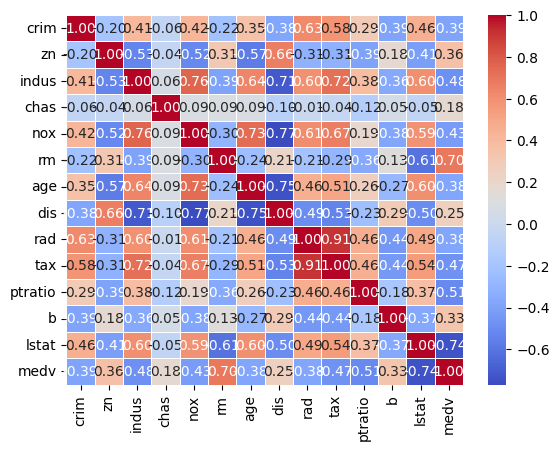

In [68]:
sns.heatmap(df.corr(),cmap="coolwarm",fmt=".2f",linewidth=0.5,annot=True)

In [69]:
X = df.drop("medv",axis=1)
y = df["medv"]
y=y.values.reshape(-1,1)
y.shape,X.shape


((506, 1), (506, 13))

In [80]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
y_scaled = scaler.fit_transform(y)
X_train,X_test,y_train,y_test = train_test_split(X_scaled,y_scaled,test_size=0.2,random_state=42)
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((404, 13), (102, 13), (404, 1), (102, 1))

In [81]:
theta = initalize_parameters(X_train.shape[1])
theta,loss = batch_compute_gradients(theta,X_train,y_train,learning_rate=0.01,n_iter=1000)

y_pred = predict(X_test,theta)

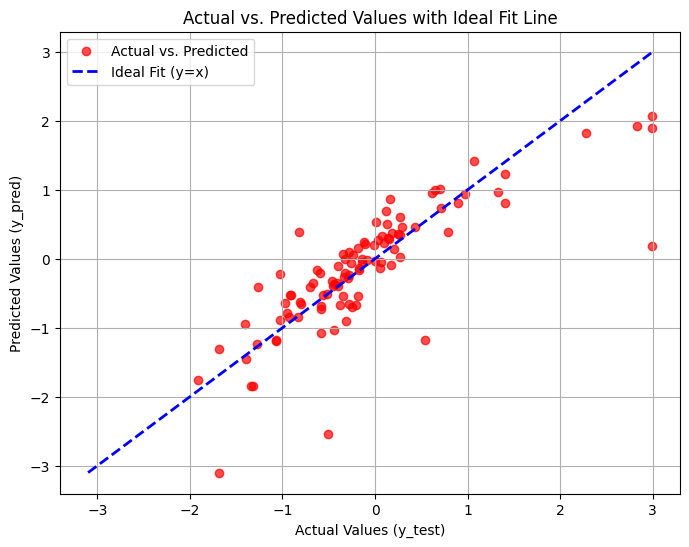

array([[ 6.87884544e-01],
       [ 1.41191528e+00],
       [-6.46271407e-01],
       [ 2.67987660e-01],
       [-4.03214689e-01],
       [ 9.87582685e-02],
       [-5.12811068e-01],
       [-8.41580878e-01],
       [-1.31756335e-03],
       [-1.66968789e-01],
       [ 2.08125314e-01],
       [-3.89221757e-01],
       [-3.09952118e+00],
       [-4.21611712e-02],
       [-3.61837034e-01],
       [ 3.85879635e-01],
       [-3.56056851e-01],
       [-1.84741451e+00],
       [ 1.89694228e+00],
       [-5.27540962e-01],
       [ 4.63129887e-01],
       [ 7.42030075e-01],
       [-1.17563982e+00],
       [ 2.05522231e-01],
       [-5.17816192e-01],
       [-7.87588869e-01],
       [ 4.86698819e-02],
       [-8.42482197e-01],
       [-2.03611479e-02],
       [-3.20089413e-01],
       [-4.45645990e-02],
       [ 3.02510490e-01],
       [ 3.84504875e-01],
       [-5.37375687e-01],
       [-6.71682165e-01],
       [-5.40233410e-01],
       [ 9.74684871e-01],
       [-2.69509690e-01],
       [ 1.3

In [83]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='red', label='Actual vs. Predicted')
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='blue', linestyle='--', linewidth=2, label='Ideal Fit (y=x)')
plt.xlabel("Actual Values (y_test)")
plt.ylabel("Predicted Values (y_pred)")
plt.title("Actual vs. Predicted Values with Ideal Fit Line")
plt.legend()
plt.grid(True)
plt.show()

y_pred

In [84]:

calculated_mse = mse(y_test,y_pred)
calculated_rmse = rmse(y_test,y_pred)
calculated_mae = mae(y_test,y_pred)
calculated_rscore = r2_score(y_test,y_pred)
print(calculated_mse, calculated_rscore)

0.3000390546815844 0.6546044301251989


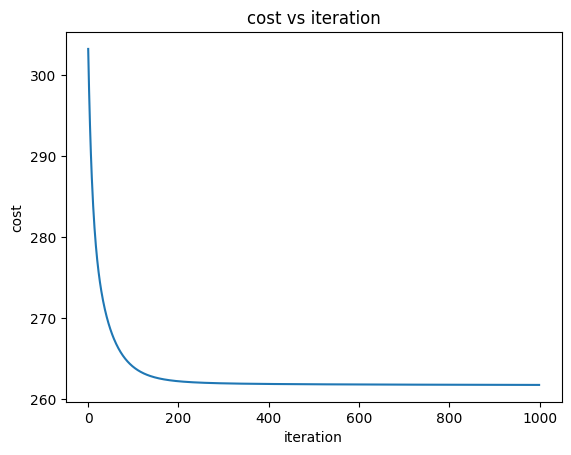

In [77]:
plt.title("cost vs iteration")
plt.xlabel("iteration")
plt.ylabel("cost")
plt.plot(cost_history)
plt.show()


ValueError: x and y must be the same size

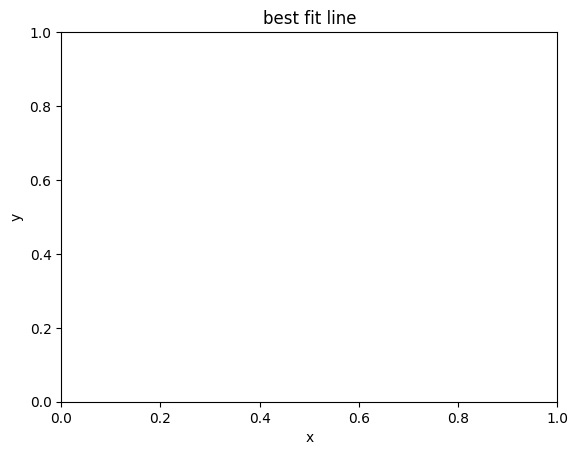

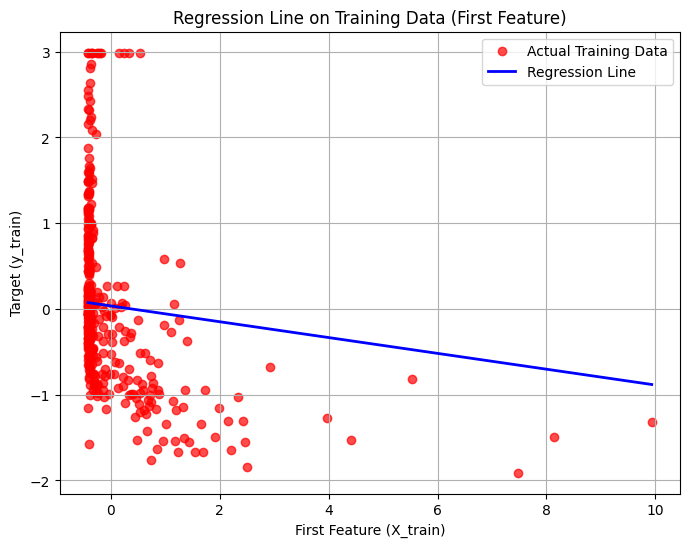

In [100]:
# Assuming we want to plot the regression line against the first feature (index 0) from X_train
num_features = X_train.shape[1]

# Create a range of values for the first feature to plot the regression line
x_plot_feature_range = np.linspace(X_train[:, 0].min(), X_train[:, 0].max(), 100).reshape(-1, 1)

# Create a matrix for prediction where the first feature varies
# and all other features are set to their mean values from the training data
X_plot_input = np.full((100, num_features), X_train.mean(axis=0))
X_plot_input[:, 0] = x_plot_feature_range.flatten() # Set the first feature to the varying range

# Predict y values for the constructed X_plot_input
y_plot_pred = predict(X_plot_input, theta)

plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], y_train, color='red', label='Actual Training Data', alpha=0.7)
plt.plot(x_plot_feature_range, y_plot_pred, color='blue', label='Regression Line', linewidth=2)
plt.xlabel('First Feature (X_train)')
plt.ylabel('Target (y_train)')
plt.title('Regression Line on Training Data (First Feature)')
plt.legend()
plt.grid(True)
plt.show()

In [105]:
np.linalg.cond(X_train.T @ X_train)

np.float64(97.92641968816741)

In [102]:
theta_normal = np.linalg.inv(X_train.T @ X_train)@X_train.T@y_train
theta_normal

array([[-0.10587592],
       [ 0.0764827 ],
       [ 0.03027897],
       [ 0.07690798],
       [-0.21720368],
       [ 0.33894109],
       [-0.01929085],
       [-0.33173728],
       [ 0.24855526],
       [-0.19503082],
       [-0.21527226],
       [ 0.12266349],
       [-0.39480444]])

In [103]:
res = np.abs(theta -theta_normal)
res

array([[0.01366714],
       [0.03073714],
       [0.03763172],
       [0.00480752],
       [0.04384794],
       [0.01839667],
       [0.00368435],
       [0.04388305],
       [0.11934907],
       [0.11836154],
       [0.01019734],
       [0.00109514],
       [0.00660385]])